# Amortized methods in geostatistics

**Check list execution**
* data_path
* res_path
* batch_size
* n_epoch

In [1]:
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

import numpy as np

import random
from tqdm import tqdm
import time
import os
import torchmin
import h5py

In [20]:
import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader

# import torch_geometric
# from torch_geometric.data import Data
# from torch_geometric.nn import global_mean_pool, GCNConv

# from torch_geometric.data import Dataset
# from torch_geometric.loader import DataLoader
# from torch_geometric.data import Batch

# from torch_geometric.utils import to_scipy_sparse_matrix
# from torch_geometric.nn.conv import MessagePassing
# from torch_geometric.utils import scatter
# from torch_geometric.nn import aggr

In [3]:
from scipy.sparse.csgraph import connected_components
from scipy.spatial import cKDTree
from scipy.optimize import minimize
import scipy.linalg as linalg
from scipy.special import gamma, kv

In [4]:
import gstlearn as gl
import gstlearn.plot as gp
import gstlearn.document as gdoc
gdoc.setNoScroll()

<IPython.core.display.Javascript object>

In [5]:
device = torch.device("cuda:1" if torch.cuda.is_available() else "cpu")

## Variables

In [503]:
data_path = "data/wallpaper_spatiotemporal_2D_small"
data_name = "samples_square.h5"

os.makedirs(data_path, exist_ok=True)
os.makedirs(data_path+"/samples", exist_ok=True)

In [504]:
# res_path = f"results/{id_path}-{n_train}×{m_train}ntrain-{n_test}×{m_test}ntest" # -{n_points}npoints"
res_path = "results/test_spationtemporal_2D"

os.makedirs(res_path, exist_ok=True)
os.makedirs(res_path+"/loss_evolution", exist_ok=True)
os.makedirs(res_path+"/conclusion_graphs", exist_ok=True)
os.makedirs(res_path+"/models", exist_ok=True)

In [505]:
batch_size = 10
n_epochs = 150
n_epochs_test = 10

In [506]:
space_size = 30
time_size = 30
deepset_size = 5
missing_ratio = 1/2

train_size = 200 # 1500 
test_size = 50 # 200 

## Utils

In [19]:
theta_names = ["advection", "range time", "range space", "std"]

theta_colors = {
    "advection":{
        "train":"orangered",
        "test":"lightsalmon",
        "baseline":"dimgrey"
    },
    "range time":{
        "train":"deepskyblue",
        "test":"lightskyblue",
        "baseline":"dimgrey"
    },
    "range space":{
        "train":"forestgreen",
        "test":"limegreen",
        "baseline":"dimgrey"
    },
    "std":{
        "train":"darkorchid",
        "test":"orchid",
        "baseline":"dimgrey"
    },
}

In [80]:
def deepset_collate(batch):
    data, theta, deepset = map(torch.stack, zip(*batch))

    data = data.flatten(0, 1)     
    theta = theta.flatten(0, 1)  
    deepset = deepset.flatten(0, 1)

    return data, theta, deepset

In [81]:
def unique_preserve_order(x):
    seen = []
    out = []
    for v in x.tolist():
        if v not in seen:
            seen.append(v)
            out.append(v)
    return torch.tensor(out, device=x.device)


def map_deepset(deepset, theta):
    unique_ds = unique_preserve_order(deepset)

    deepset_mapped = torch.tensor(
        [unique_ds.tolist().index(int(ds)) for ds in deepset],
        device=device
    )

    theta = torch.stack([theta[deepset == v][0] for v in unique_ds])

    return deepset_mapped, theta

In [82]:
def baseline_mae(dataset):
    all_thetas = dataset.get_theta()
    
    theta_mean = all_thetas.mean(dim=0) 
    
    preds = theta_mean.unsqueeze(0).repeat(len(dataset), 1)
    
    mae = torch.mean(torch.abs(preds - all_thetas),dim=0)

    return mae, theta_mean

In [83]:
def global_mean_pool(x, batch):
    num_groups = batch.max().item() + 1
    out = torch.zeros(num_groups, x.size(1), device=x.device)
    out.index_add_(0, batch, x)
    return out / torch.bincount(batch).float().unsqueeze(1)

## Simulation

In [19]:
n_all = 1
sample_size = [30, 30] # [2560,2560]

In [20]:
def simulation_matern(path, n, sizes=[1200,1200], ranges=[1e-2,1e-2]):

    model = gl.Model.createFromParam(gl.ECov.MATERN, ranges = ranges, param = 1, sill = 1**2, flagRange=False)
    
    grid = gl.DbGrid.create(nx = sizes, dx = [1./sizes[0],1./sizes[1]])
    mesh = gl.MeshETurbo(grid)

    pop = gl.PrecisionOp(mesh, model.getCovAniso(0))

    t = tqdm(range(0, n),total=n)

    with h5py.File(path, 'w') as hdf:
        dset = hdf.create_dataset(
            'samples',
            shape=(n, sizes[0], sizes[1]),
            dtype='float64',
            compression='gzip',          
            chunks=(1, sizes[0], sizes[1])
        )
    
        for i in t:
            res = pop.simulateOne()
            dset[i] = res.reshape((sizes[0], sizes[1]))
        


In [21]:
simulation_matern(data_path + '/' + data_name, n=n_all, sizes=sample_size, ranges=[1e-1,1e-1])

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00,  3.04it/s]


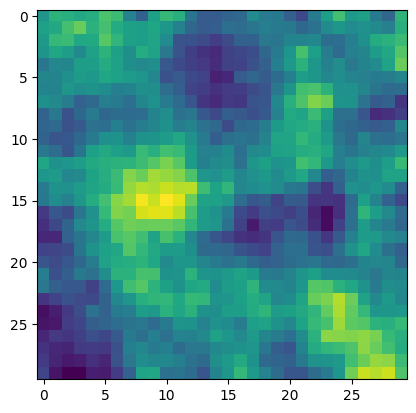

In [22]:
with h5py.File(data_path + '/' + data_name, 'r') as hdf:
    batch = hdf['samples'][0]
plt.imshow(batch)

# width_px = 2560
# height_px = 1440
# dpi = 100

# fig = plt.figure(figsize=(width_px/dpi, height_px/dpi), dpi=dpi)
# ax = plt.Axes(fig, [0., 0., 1., 1.]) 
# fig.add_axes(ax)

# ax.imshow(batch[:1440, :2560], cmap='bone') #cividis # YlGn # Pastel1 # bone # copper
# ax.axis('off')

# plt.savefig(
#     'wallpaper3.png',
#     dpi=dpi,
#     pad_inches=0
# )

# plt.close()

## Load

In [413]:
batch_size = 5
n_epochs = 50
n_epochs_test = 10

In [414]:
space_size = 40
time_size = 40
deepset_size = 4

In [516]:
class GridDataset(Dataset):
    def __init__(self, path, all_idx, deepset_size, time_size = 20, space_size = 20, data_shape=[1200,1200]):
        
        self.path = path
        self.hdf = None
        
        self.all_idx = all_idx
        self.space_size = space_size
        self.time_size = time_size
        self.data_shape = data_shape
        self.deepset_size = deepset_size

        adv = torch.randint(-3,4,(len(all_idx),)) 
        range_space = torch.randint(2,10,(len(all_idx),)) # torch.ones((batch_size,), dtype=int)*1
        range_time = torch.randint(2,10,(len(all_idx),))
        
        self.theta = torch.stack([adv,range_time, range_space]).T

    def __len__(self):
        return len(self.all_idx)


    def _init_hdf(self):
        if self.hdf is None:
            self.hdf = h5py.File(self.path, 'r')

    def __getitem__(self, idx):

        self._init_hdf()

        time_0 = time.time()

        adv = self.theta[idx,0].tile(self.deepset_size)
        range_space = self.theta[idx,1].tile(self.deepset_size)
        range_time = self.theta[idx,2].tile(self.deepset_size)
        

        space_min = torch.maximum(- adv * self.time_size, torch.zeros_like(adv))
        space_max = self.data_shape[1] - torch.maximum(adv * self.time_size, torch.zeros_like(adv)) - self.space_size * range_space
        
        init_space = torch.randint(2**32 - 1, size=(self.deepset_size,)) % (space_max - space_min) + space_min
        init_space = init_space.tile((self.space_size, 1)).T
        init_space += torch.arange(self.space_size).tile((self.deepset_size, 1)) * range_space.unsqueeze(1)
        

        time_max = self.data_shape[0] - range_time * self.time_size
        
        init_time = torch.randint(2**32 - 1, size=(self.deepset_size,)) % time_max
        init_time = init_time.tile((self.time_size, 1)).T
        init_time += torch.arange(self.time_size).tile((self.deepset_size, 1)) * range_time.unsqueeze(1)
        

        space2 = init_space.unsqueeze(1).tile(1,self.time_size, 1)   
        time2  = init_time.unsqueeze(2).tile(1,self.space_size) 

        offset = torch.arange(self.time_size).tile(self.deepset_size,self.space_size,1).transpose(1,2) * adv.unsqueeze(1).unsqueeze(2)
        space2 = space2 + offset
        
        # time_1 = time.time()
        # print("space2 and time2 :",time_1 - time_0)

        theta = torch.stack([adv,range_time, range_space]).T

        deepset = torch.arange(self.deepset_size) # torch.tensor([i for i in range(self.deepset_size) if not(theta[i] in theta[:i])])

        # time_2 = time.time()
        # print("theta and deepset :", time_2 - time_1)

        # idx_rand, _ = torch.sort(torch.randperm(self.all_idx[-1] - self.all_idx[0])[:self.deepset_size])
        start = torch.randint(self.all_idx[0], self.all_idx[-1] - self.deepset_size, (1,)).item()
        idx_rand = torch.arange(start, start + self.deepset_size)
        
        samples = self.hdf['samples']
        batch = samples[idx_rand]
        

        plt.imshow(batch[0].T, origin='lower')
        plt.scatter(space2[0].flatten(), time2[0].flatten(), c='red',s=.1)
        plt.title(theta[0])
        plt.show()
        

        # with h5py.File(self.path, 'r') as hdf:
        #     batch = hdf['samples'][idx_rand] 

        # time_3 = time.time()
        # print("load : ",time_3 - time_2)

        batch = batch[torch.arange(self.deepset_size).unsqueeze(1).unsqueeze(2), time2, space2]

        # time_4 = time.time()
        # print("extract : ",time_4 - time_3)
        
        return (torch.from_numpy(batch), theta, deepset)           

In [517]:
dataset_grid = GridDataset(data_path + '/' + data_name, torch.arange(180), deepset_size, time_size = 40, space_size = 20)
dataset_grid_test = GridDataset(data_path + '/' + data_name, torch.arange(180, 200), deepset_size)

loader_grid = DataLoader(
    dataset_grid,
    batch_size=batch_size,
    shuffle=True,
    # num_workers=4,        
    # persistent_workers=True,
    # collate_fn=collate_fn
)
loader_grid_test = DataLoader(dataset_grid_test, 20, shuffle=False)

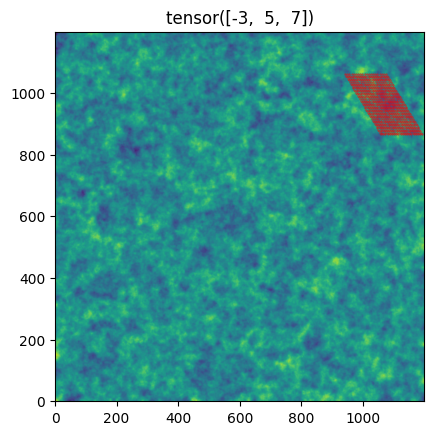

In [518]:
# batch_test = dataset_grid[1]
# plt.imshow(batch_test[0][0])
# print(batch_test[1])
batch_test = dataset_grid[9]

In [515]:
fig, ax = plt.subplots(figsize=(5,5))

def update(i):
    ax.cla()
    ax.imshow(batch_test[0][i])
    # ax.set_xlim(0,1)
    # ax.set_ylim(0,1)
    ax.set_title(f"Theta {batch_test[1][i]}")

ani = FuncAnimation(fig, update, frames=len(batch_test[0]), interval=300)

plt.close()

HTML(ani.to_jshtml())

## Simulation and Load 2

In [269]:
def simulate_matern_grid(time_size, space_size, adv, range_time, range_space, std, deepset_size=5):
    
    model = gl.Model.createFromParam(gl.ECov.MATERN, ranges = [range_time,range_space], param = 1, sill = std**2, flagRange=False)

    shape_adv = abs(adv)+1

    grid = gl.DbGrid.create(
        nx = [time_size,space_size  + time_size*shape_adv],    
        dx = [1./time_size,1./space_size]
    )

    mesh = gl.MeshETurbo(grid)

    pop = gl.PrecisionOpMatrix(mesh, model.getCovAniso(0))

    batch = []
        
    for i in range(deepset_size):
            
        res = pop.simulateOne()
        res = res.reshape((time_size,space_size + time_size*shape_adv), order='F')

        t, s = np.meshgrid(np.arange(time_size), np.arange(space_size), indexing='ij')
        offset = t.copy() * abs(adv)
        s = s + offset


        if adv >= 0 :
            res = res[t,s]
        else :
            res = np.fliplr(res)
            res = res[t,s]
            res = np.fliplr(res)
            
        batch.append(res)

    return np.expand_dims(np.stack(batch),1)

In [270]:
def add_missing_mask(batch, missing_ratio):
    nb_missing = int(space_size*missing_ratio)
    missings = np.sort(np.random.permutation(space_size)[:nb_missing])
    batch[:,:,:,missings] = 0
    mask = np.zeros_like(batch)
    mask[:,:,:,missings] = 1
    return np.concatenate([batch, mask], axis=1) 

In [271]:
class GridDataset(Dataset):
    def __init__(self, theta_size=200, time_size=40, space_size=40, deepset_size=5, missing_ratio=0):

        self.time_size = time_size
        self.space_size = space_size
        
        self.theta_size = theta_size
        self.deepset_size = deepset_size

        self.adv = np.random.randint(-3,4,(theta_size,)) # np.ones((theta_size,), dtype=int)*-1
        self.range_time = np.random.uniform(0.05,0.25,(theta_size,)) 
        self.range_space = np.random.uniform(0.05,0.25,(theta_size,))
        self.std = np.random.uniform(0.1,1.,(theta_size,))

        self.missing_ratio = missing_ratio

    def __len__(self):
        return self.theta_size

    def get_theta(self):
        return torch.from_numpy(np.stack([self.adv,self.range_time, self.range_space, self.std]).T)

    def save(self, path):
        param = {
            "time_size" : self.time_size,
            "space_size" : self.space_size,
            "theta_size" : self.theta_size,
            "deepset_size" : self.deepset_size,
            "adv" : self.adv,
            "range_time" : self.range_time,
            "range_space" : self.range_space,
            "std" : self.std,
        }
        torch.save(param, path)  

    def __getitem__(self, idx):

        batch = simulate_matern_grid(
            self.time_size, self.space_size, 
            self.adv[idx], self.range_time[idx], self.range_space[idx],
            self.std[idx],
            self.deepset_size
        )

        if self.missing_ratio > 0 :
            batch = add_missing_mask(batch, self.missing_ratio)

        theta = self.get_theta()[idx].tile(self.deepset_size,1)

        deepset = torch.ones(self.deepset_size, dtype=int) * idx # torch.tensor([i for i in range(self.deepset_size) if not(theta[i] in theta[:i])])

        return (torch.from_numpy(batch), theta, deepset)           

In [272]:
dataset_grid = GridDataset(theta_size=train_size, time_size=time_size, space_size=space_size, deepset_size=deepset_size,missing_ratio=missing_ratio)
dataset_grid_test = GridDataset(theta_size=test_size, time_size=time_size, space_size=space_size, deepset_size=1,missing_ratio=missing_ratio)

loader_grid = DataLoader(dataset_grid, batch_size=batch_size, shuffle=True,collate_fn=deepset_collate)
loader_grid_test = DataLoader(dataset_grid_test, test_size, shuffle=False,collate_fn=deepset_collate)

In [273]:
dataset_grid.save(data_path + '/' + data_name)
dataset_grid_test.save(data_path + '/' + data_name)

Text(0.5, 1.0, 'mask')

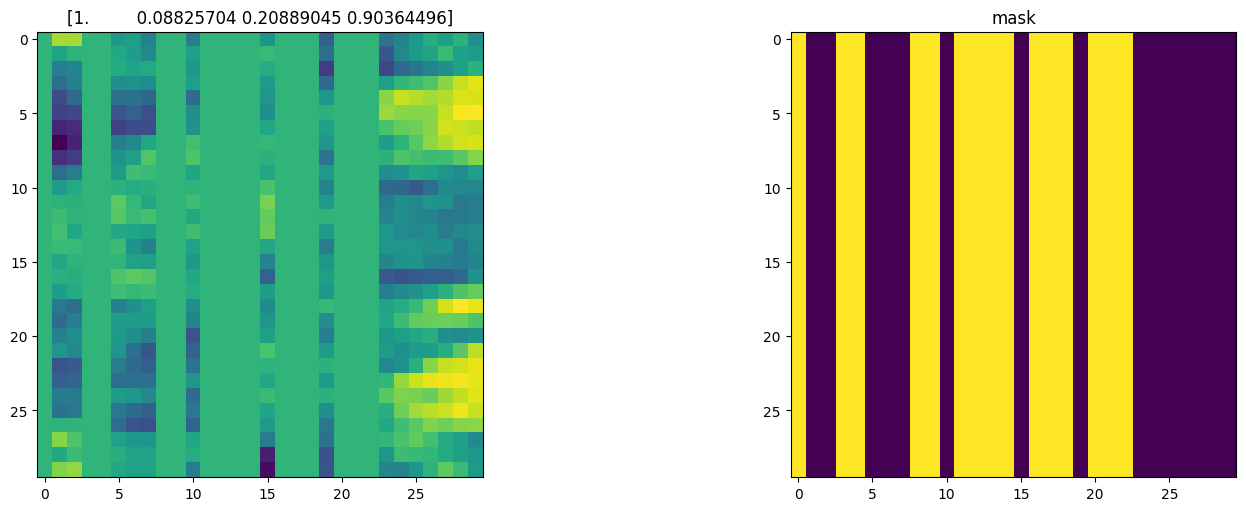

In [274]:
m=0
im = dataset_grid[0]
fig, ax = plt.subplots(1, 2, figsize=(15, 5), constrained_layout=True)
ax[0].imshow(im[0][m][0], aspect='equal')
ax[0].set_title(im[1][m].detach().numpy())
ax[1].imshow(im[0][m][1], aspect='equal')
ax[1].set_title("mask")

Text(0.5, 1.0, '[-2.          0.18522704  0.17499867  0.84577327]')

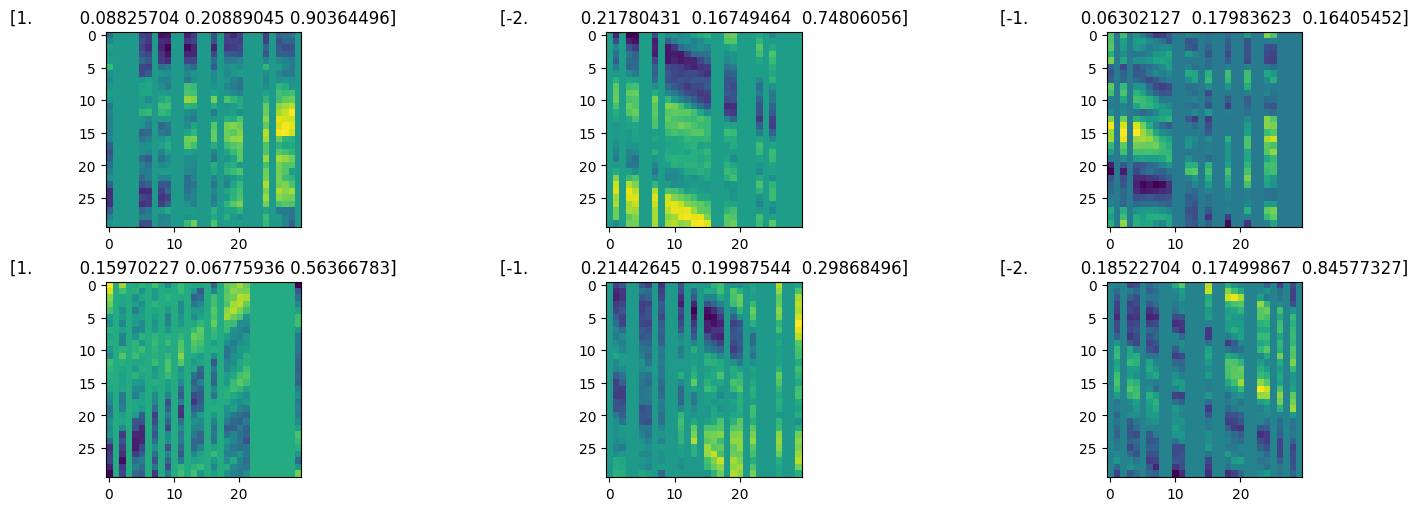

In [275]:
m=0
fig, ax = plt.subplots(2, 3, figsize=(15, 5), constrained_layout=True)
ax[0,0].imshow(dataset_grid[0][0][m][0], aspect='equal')
ax[0,0].set_title(dataset_grid[0][1][m].detach().numpy())
ax[0,1].imshow(dataset_grid[1][0][m][0], aspect='equal')
ax[0,1].set_title(dataset_grid[1][1][m].detach().numpy())
ax[0,2].imshow(dataset_grid[2][0][m][0], aspect='equal')
ax[0,2].set_title(dataset_grid[2][1][m].detach().numpy())
ax[1,0].imshow(dataset_grid[3][0][m][0], aspect='equal')
ax[1,0].set_title(dataset_grid[3][1][m].detach().numpy())
ax[1,1].imshow(dataset_grid[4][0][m][0], aspect='equal')
ax[1,1].set_title(dataset_grid[4][1][m].detach().numpy())
ax[1,2].imshow(dataset_grid[5][0][m][0], aspect='equal')
ax[1,2].set_title(dataset_grid[5][1][m].detach().numpy())

## Simulation and Load 3

In [482]:
def variogram(u, alpha=1.0, b=1.0):
    """Variogram: gamma(u) = (|u|/b)^alpha"""
    return (np.abs(u) / b) ** alpha

def matern_cov(h, nu=1.5, a=1.0):
    """Matern isotropic covariance function"""
    d = np.abs(h)
    res = np.ones_like(d)
    mask = d > 0
    
    if np.any(mask):
        d_val = d[mask]
        const = 2.0 / gamma(nu)
        term = (d_val / (2.0 * a)) ** nu
        bessel = kv(nu, d_val / a)
        res[mask] = const * term * bessel
        
    return res

def sim_w(p, Nt, params):
    """
    Simulates p copies of temporal processes W with temporal variogram 
    gamma*(u) = (gamma(u)+1)^beta - 1
    """
    # Params: [nu, a, alpha, b, beta, delta, k]
    alpha, b_param, beta = params[2], params[3], params[4]

    t_indices = np.arange(1, Nt + 1)
    
    c1 = (variogram(-t_indices, alpha=alpha, b=b_param) + 1.0) ** beta - 1.0
    
    diff_matrix = t_indices[:, None] - t_indices[None, :]
    cc_term = (variogram(diff_matrix, alpha=alpha, b=b_param) + 1.0) ** beta - 1.0
    
    cc = c1[:, None] + c1[None, :] - cc_term
    
    L = np.linalg.cholesky(cc + 1e-10 * np.eye(Nt))
    
    X = np.random.normal(size=(Nt, p))
    
    W = L @ X
    return W.T 

def sim_z1(p, Nt, params):
    """
    Simulates p copies of temporal processes Z1 with temporal covariance function
    gamma*(u) = (gamma(u)+1)^(-delta)
    """
    alpha, b_param, delta = params[2], params[3], params[5]

    t_indices = np.arange(1, Nt + 1)
    diff_matrix = t_indices[:, None] - t_indices[None, :]
    cc = 1.0 / (variogram(diff_matrix, alpha=alpha, b=b_param) + 1.0) ** delta
    
    L = np.linalg.cholesky(cc + 1e-10 * np.eye(Nt))
    X = np.random.normal(size=(Nt, p))
    
    Z = L @ X
    return Z.T # (p, Nt)

def sim_rvs(p, params):
    """
    Simulates all necessary Random Variables for the 
    spectral band simulation algorithm with substitution approach
    """
    nu, a = params[0], params[1]
    k = params[6] 
    
    r_gamma = np.random.gamma(shape=nu, scale=2 * (a**2), size=p)
    
    R_val = 1.0 / (2.0 * r_gamma)
    multR = np.sqrt(2.0 * R_val)
    
    Phi = 2 * np.pi * np.random.uniform(size=p)
    
    U_rand = np.random.uniform(size=p)
    UU = np.sqrt(-2.0 * np.log(U_rand))
    
    Omega = np.random.normal(size=(k, p))
    
    return {
        "UU": UU,       # (p,)
        "multR": multR, # (p,)
        "Omega": Omega, # (k, p)
        "Phi": Phi      # (p,)
    }

def ztilde_t_vecs(s, t_idx, rvs, W, Z1, sigma):
    """
    Do the computation of the simulated RF
    s: coordinates (Ns, k)
    t_idx: time (0 to Nt-1)
    """
    UU = rvs["UU"]       
    multR = rvs["multR"] 
    Omega = rvs["Omega"] 
    Phi = rvs["Phi"]     
    
    nOmega = np.linalg.norm(Omega, axis=0) # (p,)
    
    ww_t = W[:, t_idx]   # (p,)
    zz_t = Z1[:, t_idx]  # (p,)
    
    p = len(UU)
    
    spatial_proj = s @ Omega 
    term_cos = (spatial_proj * multR) + (nOmega * ww_t / np.sqrt(2)) + Phi
    V = np.cos(term_cos)
    
    V = V * UU * zz_t
    
    field_t = np.sum(V, axis=1) / np.sqrt(p)
    
    return field_t * sigma

def simulate_spatio_temporal(params_dict, Nt, s_coords):
    k = 1
    p = 3000 
    
    nu = params_dict['smooth_s']
    a = params_dict['scale_s']
    alpha = params_dict['power_t']
    b = params_dict['scale_t']
    bet = params_dict['sep']
    
    delta = params_dict['power2_t'] - bet
    
    sim_params = [nu, a, alpha, b, bet, delta, k]
    
    sigma = np.sqrt(params_dict['sill'])
    
    t0 = time.time()
    W = sim_w(p, Nt, sim_params)   # (p, Nt)
    Z1 = sim_z1(p, Nt, sim_params) # (p, Nt)
    RVs = sim_rvs(p, sim_params)
    
    Ns = s_coords.shape[0]
    Z_field = np.zeros((Ns, Nt))
    
    # Loop on time (space in vectorized)
    for t in range(Nt):
        Z_field[:, t] = ztilde_t_vecs(s_coords, t, RVs, W, Z1, sigma)
            
    return Z_field

In [483]:
Ns_side = 30
Nt = 30
    
s = np.expand_dims(np.arange(1, Ns_side + 1),1)
    
params = {
    # Advection ?
    'mean': 0,
    'sill': 1.0,       #* std ?
    'smooth_s': 1.0,   #  Matérn Shape parameter 
    'scale_s': 10.0,    #* Spatial range parameter
    'power_t': 0.5,    #  Shape parameter (of the variogram \gamma(u) used in time)
    'scale_t': 1.,     #* Range parameter in time (of the variogram \gamma(u) used in time)
    'sep': 0.2,        #* Separability parameter (between 0 and 1)
    'power2_t': 0.4    #  Power in the time covariance of the time process ( > 0 )
}
    
Z_sim = simulate_spatio_temporal(params, Nt, s).T

In [496]:
class GridDatasetSep(Dataset):
    def __init__(self, theta_size=200, time_size=40, space_size=40, deepset_size=5, missing_ratio=0):

        self.time_size = time_size
        self.space_size = space_size
        
        self.theta_size = theta_size
        self.deepset_size = deepset_size

        self.sep = np.log10(np.random.uniform(1.,2.,(theta_size,)))
        self.scale_time = np.random.uniform(1.,10.,(theta_size,)) 
        self.scale_space = np.random.uniform(1.,10.,(theta_size,))
        self.sill = np.random.uniform(.1,1.,(theta_size,))            # np.ones((theta_size,), dtype=int)*-1

        self.missing_ratio = missing_ratio

    def __len__(self):
        return self.theta_size

    def get_theta(self):
        return torch.from_numpy(np.stack([self.sep,self.scale_time, self.scale_space, self.sill]).T)

    def save(self, path):
        param = {
            "time_size" : self.time_size,
            "space_size" : self.space_size,
            "theta_size" : self.theta_size,
            "deepset_size" : self.deepset_size,
            "sill" : self.sill,
            "scale_time" : self.scale_time,
            "scale_space" : self.scale_space,
            "sep" : self.sep,
        }
        torch.save(param, path)

    def __getitem__(self, idx):

        s = np.expand_dims(np.arange(1, self.space_size + 1),1)

        batch = []
        for i in range(deepset_size):

            params = {
                # Advection ?
                'mean': 0,
                'sill': self.sill[idx],       
                'smooth_s': 1.0,   
                'scale_s': self.scale_space[idx],    
                'power_t': 0.5,    
                'scale_t': self.scale_time[idx],     
                'sep': self.sep[idx],        
                'power2_t': self.sep[idx]*2
            }
            
            batch.append(simulate_spatio_temporal(params, self.time_size, s).T)
        batch = np.expand_dims(np.stack(batch), 1)

        if self.missing_ratio > 0 :
            batch = add_missing_mask(batch, self.missing_ratio)

        theta = self.get_theta()[idx].tile(self.deepset_size,1)

        deepset = torch.ones(self.deepset_size, dtype=int) * idx # torch.tensor([i for i in range(self.deepset_size) if not(theta[i] in theta[:i])])

        return (torch.from_numpy(batch), theta, deepset)           

In [497]:
dataset_sep = GridDatasetSep(theta_size=train_size, time_size=time_size, space_size=space_size, deepset_size=deepset_size,missing_ratio=missing_ratio)
dataset_sep_test = GridDatasetSep(theta_size=test_size, time_size=time_size, space_size=space_size, deepset_size=1,missing_ratio=missing_ratio)

loader_sep = DataLoader(dataset_sep, batch_size=batch_size, shuffle=True,collate_fn=deepset_collate)
loader_sep_test = DataLoader(dataset_sep_test, test_size, shuffle=False,collate_fn=deepset_collate)

Text(0.5, 1.0, 'mask')

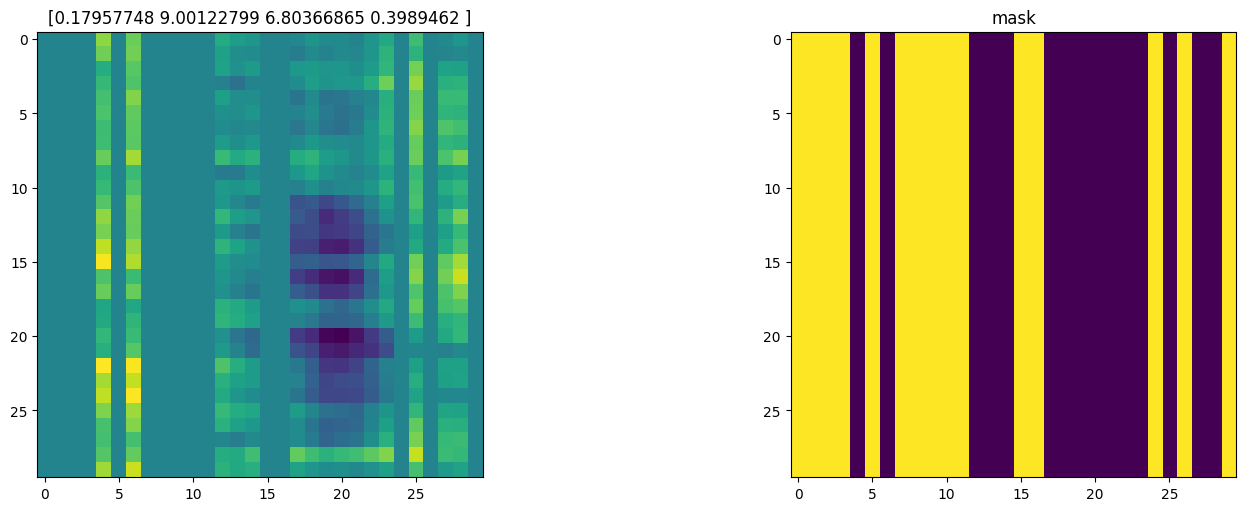

In [500]:
m=0
im = dataset_sep[0]
fig, ax = plt.subplots(1, 2, figsize=(15, 5), constrained_layout=True)
ax[0].imshow(im[0][m][0], aspect='equal')
ax[0].set_title(im[1][m].detach().numpy())
ax[1].imshow(im[0][m][1], aspect='equal')
ax[1].set_title("mask")

Text(0.5, 1.0, '[0.16847115 8.20823061 5.96248198 0.11590078]')

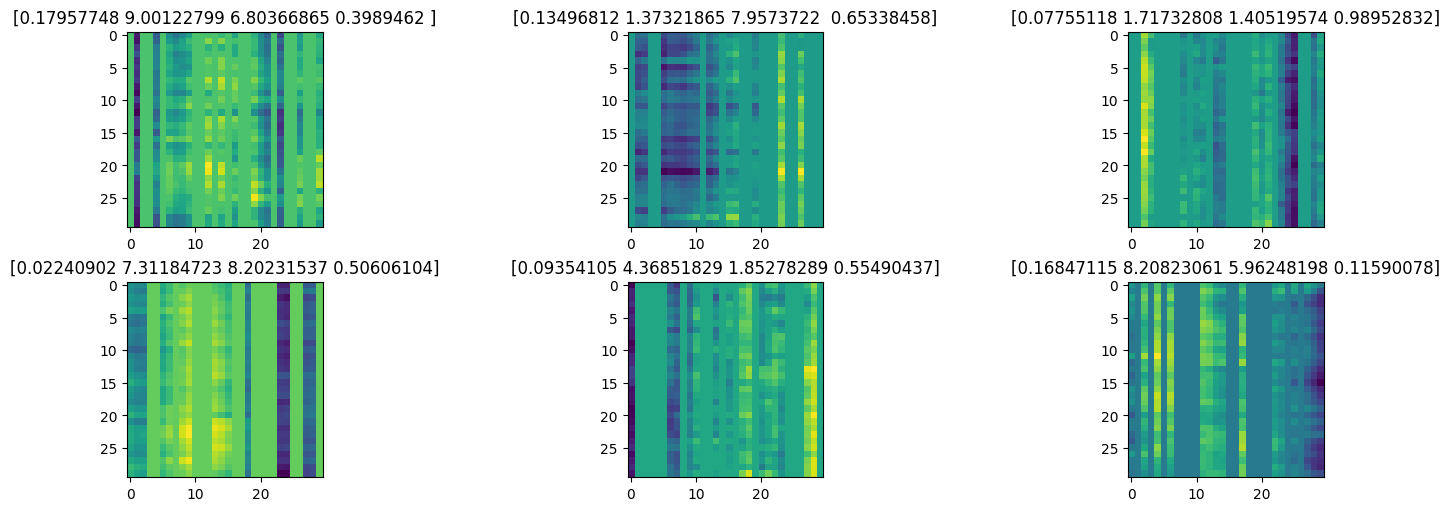

In [501]:
m=0
fig, ax = plt.subplots(2, 3, figsize=(15, 5), constrained_layout=True)
ax[0,0].imshow(dataset_sep[0][0][m][0], aspect='equal')
ax[0,0].set_title(dataset_sep[0][1][m].detach().numpy())
ax[0,1].imshow(dataset_sep[1][0][m][0], aspect='equal')
ax[0,1].set_title(dataset_sep[1][1][m].detach().numpy())
ax[0,2].imshow(dataset_sep[2][0][m][0], aspect='equal')
ax[0,2].set_title(dataset_sep[2][1][m].detach().numpy())
ax[1,0].imshow(dataset_sep[3][0][m][0], aspect='equal')
ax[1,0].set_title(dataset_sep[3][1][m].detach().numpy())
ax[1,1].imshow(dataset_sep[4][0][m][0], aspect='equal')
ax[1,1].set_title(dataset_sep[4][1][m].detach().numpy())
ax[1,2].imshow(dataset_sep[5][0][m][0], aspect='equal')
ax[1,2].set_title(dataset_sep[5][1][m].detach().numpy())

## General functions

In [507]:
class CNN_network(nn.Module):
    def __init__(self, in_channels=2, hidden=32, out_dim=4, option="2D-CNN", nls=False):
        super().__init__()

        self.option_type = option
        self.nls = nls

        if option == "2D-CNN" : 
        
            self.conv2d = nn.Sequential(
                nn.Conv2d(in_channels=in_channels, out_channels=hidden, kernel_size=5, stride=1, padding=1),
                nn.ReLU(),
                nn.Conv2d(in_channels=hidden, out_channels=hidden, kernel_size=3, stride=1, padding=1),
                nn.ReLU(),
            )
            
            self.pool2d = nn.AdaptiveAvgPool2d(1) 

        else : 

            self.conv1d = nn.Sequential(
                nn.Conv1d(in_channels=in_channels, out_channels=hidden, kernel_size=5, stride=1, padding=1),
                nn.ReLU(),
                nn.Conv1d(in_channels=hidden, out_channels=hidden, kernel_size=3, stride=1, padding=1),
                nn.ReLU(),
            )
            
            self.pool1d = nn.AdaptiveAvgPool1d(1) 
    
            if option == "CNN" :
            
                self.conv1d_T = nn.Sequential(
                    nn.Conv1d(in_channels=hidden, out_channels=hidden, kernel_size=5, stride=1, padding=1),
                    nn.ReLU(),
                    nn.Conv1d(in_channels=hidden, out_channels=hidden, kernel_size=3, stride=1, padding=1),
                    nn.ReLU(),
                )
    
            elif option == "LSTM" :
    
                self.lstm = nn.LSTM(input_size=hidden, hidden_size=hidden, num_layers=2, batch_first=True, bidirectional=False)  

        
        self.dense = nn.Sequential(
            nn.Linear(hidden+4*nls, hidden),
            nn.ReLU(),
            nn.Linear(hidden, out_dim)  
        )

    def forward(self, x, deepset=None, theta=None):
        
        B,C,T,S = x.shape

        # print(x.shape)

        if self.option_type == "2D-CNN" :

            summary = self.conv2d(x)

            summary = self.pool2d(summary).view(B, -1)

        else : 

            x = x.permute(0,3,1,2).reshape(B*T, C, S)  
    
            # print(x.shape)
    
            time_summary = self.conv1d(x)                               # (B*T,hidden_dim,S)
            time_summary = self.pool1d(time_summary).view(B*T,-1)       # (B*T,hidden_dim)
    
            # print(time_summary.shape)
    
            time_summary = time_summary.view(B, T, -1).permute(0, 2, 1)                        # (B, hidden_dim, T)
    
            # print(time_summary.shape)
    
            if self.option_type == "CNN":
                summary = self.conv1d_T(time_summary)            # (B,hidden+1,T)
                summary = summary.mean(dim=2)                    # (B,hidden+1)
                
            elif self.option_type == "LSTM":    
                time_summary = time_summary.permute(0,2,1)       # (B,T,hidden+1)
                summary,_ = self.lstm(time_summary)              # (B,T,hidden+1)
                summary = summary.mean(dim=1)                    # (B,hidden+1)
    
        # print(summary.shape)
    
        if not self.nls :
            summary = global_mean_pool(summary, deepset)   # [nb_deepset, hidden_dim]
        else :
            summary = torch.cat((summary, theta.float()),dim=1)

        # print(summary.shape)
        
        out = self.dense(summary)
        return out

In [508]:
def train_test(model, optimizer, loader, epoch_loss):
    all_loss_train = [] 
    all_loss_test = []

    loss_final_train = None
    theta_final_test = None
    
    t = tqdm(range(0, n_epochs),total=n_epochs)
    
    time_train = time.time()
    time_simu = 0
    
    for epoch in t:
        
        losses, t_time_simu = epoch_loss(model, optimizer, loader, save_full=(epoch == n_epochs-1))
        time_simu += t_time_simu
    
        t.set_description(f"Epoch {epoch+1}/{n_epochs}")
        t.set_postfix(loss=f"{losses["mean"][0]:.4f}, {losses["mean"][1]:.4f}, {losses["mean"][2]:.4f} and {losses["mean"][3]:.4f}")

        all_loss_train.append(losses["mean"])   

        if "full" in losses:                          
            loss_final_train = losses["full"] 
            
        if (epoch+1)%n_epochs_test == 0 :
                
            time_test = time.time()
                
            for data_test, theta_test, deepset_test in loader_grid_test :
                    
                output = model(data_test.float(), torch.arange(len(theta_test)))
                loss_vec = torch.abs(output - theta_test)

                all_loss_test.append(loss_vec.mean(dim=0).detach().cpu())

                theta_final_test = output.detach().cpu()
                    
            time_test = time.time() - time_test
            time_train -= time_test
    
    time_train = time.time() - time_train - time_simu
    
    print(f"Time to train : {time_train:.2f}s")
    
    print(f"Train loss : adv {all_loss_train[-1][0].tolist()} | range time {all_loss_train[-1][1].tolist()} | range space {all_loss_train[-1][2].tolist()} | std {all_loss_train[-1][3].tolist()}")

    print(f"Test loss : adv {all_loss_test[-1][0].tolist()} | range time {all_loss_test[-1][1].tolist()} | range space {all_loss_test[-1][2].tolist()} | std {all_loss_test[-1][3].tolist()}")
    return all_loss_train, time_train, loss_final_train, all_loss_test, time_test, theta_final_test, time_simu


def train_simple(model, optimizer, loader, epoch_loss):
    all_loss_train = [] 

    loss_final_train = None
    
    t = tqdm(range(0, n_epochs),total=n_epochs)
    
    time_train = time.time()
    
    for epoch in t:
        
        losses = epoch_loss(model, optimizer, loader)
    
        t.set_description(f"Epoch {epoch+1}/{n_epochs}")
        t.set_postfix(loss=losses)

        all_loss_train.append(losses["mean"])   

        if "full" in losses:                          
            loss_final_train = losses["full"] 
    
    time_train = time.time() - time_train
    
    print(f"Time to train : {time_train:.2f}s")
    
    print("Train loss :", all_loss_train[-1])

    return all_loss_train, time_train

## CNN

### Functions

In [509]:
def epoch_cnn(model, optimizer, loader, save_full=False):
    
    model.train()
    MAE = torch.nn.L1Loss(reduction="none")
    
    losses_theta0 = []
    losses_theta1 = []
    losses_theta2 = []
    losses_theta3 = []
    full_losses = [] 

    time_simu = 0

    t_time_simu = time.time()

    for i, (batched_data, theta, deepset) in enumerate(loader):
        
        time_simu += time.time() - t_time_simu
        
        optimizer.zero_grad()

        batched_data, theta, deepset = batched_data.to(device).float(), theta.to(device), deepset.to(device) 

        deepset_mapped, theta = map_deepset(deepset, theta)
        
        output = model(batched_data, deepset_mapped)
        
        loss_vec = MAE(output, theta)
        
        loss = loss_vec.mean()
        loss.backward()
        optimizer.step()

        losses_theta0.append(loss_vec[:,0].mean().item())
        losses_theta1.append(loss_vec[:,1].mean().item())
        losses_theta2.append(loss_vec[:,2].mean().item())
        losses_theta3.append(loss_vec[:,3].mean().item())

        if save_full:                             
            full_losses.append(loss_vec.detach().cpu())

        t_time_simu = time.time()

    mean = torch.tensor([np.mean(losses_theta0), np.mean(losses_theta1), np.mean(losses_theta2), np.mean(losses_theta3)]).detach().cpu()
    # std  = torch.tensor([np.std(losses_theta0),  np.std(losses_theta1)])

    result = {
        "mean": mean, 
        # "std": std
    }

    if save_full:
        result["full"] = torch.cat(full_losses, dim=0)    

    return result, time_simu


In [510]:
def plot_loss(all_loss_train_grid, all_loss_test_grid):
    fig_cnn, ax = plt.subplots(1, len(theta_names), figsize=(20, 7), constrained_layout=True)
    based, _ = baseline_mae(dataset_grid)

    for i, name in enumerate(theta_names):
    
        ax[i].plot([l[i] for l in all_loss_train_grid], theta_colors[name]['train'], label='train '+name)
        ax[i].plot(np.arange(n_epochs_test,n_epochs+1,n_epochs_test),[l[i] for l in all_loss_test_grid], theta_colors[name]['test'], label='test '+name)
        
        ax[i].axhline(based[i],color=theta_colors[name]['baseline'], ls='--', label='baseline '+name)
        
        ax[i].set_title('Evolution of '+name)
        ax[i].set_xlabel('epochs')
        ax[i].set_ylabel('MAE')
        ax[i].legend()

    return fig_cnn

### Train and Test

In [511]:
model_2D = CNN_network(in_channels=2, option="2D-CNN").to(device)

optimizer_2D = torch.optim.Adam(model_2D.parameters(), lr=5e-5)

all_loss_train_2D, time_train_2D, loss_final_train_2D, all_loss_test_2D, time_test_2D, theta_final_test_2D, time_simu_2D = train_test(model_2D, optimizer_2D, loader_grid, epoch_cnn)
fig_2D = plot_loss(all_loss_train_2D, all_loss_test_2D)

Epoch 1/150:   1%|▊                                                                                                                              | 1/150 [00:54<2:15:22, 54.51s/it, loss=1.7203, 0.0538, 0.2886 and 0.3808]


KeyboardInterrupt: 

In [281]:
fig_2D.savefig(res_path+"/loss_evolution"+"/2D_train_evolution.png", format="png", bbox_inches="tight")

torch.save(model_2D.state_dict(), res_path+"/models"+"/2D_model.pth")

In [239]:
model_1D1D = CNN_network(in_channels=2, option="CNN").to(device)

optimizer_1D1D = torch.optim.Adam(model_1D1D.parameters(), lr=5e-5)

all_loss_train_1D1D, time_train_1D1D, loss_final_train_1D1D, all_loss_test_1D1D, time_test_1D1D, theta_final_test_1D1D, time_simu_1D1D = train_test(model_1D1D, optimizer_1D1D, loader_grid, epoch_cnn)
fig_1D1D = plot_loss(all_loss_train_1D1D, all_loss_test_1D1D)

Epoch 1/50:   2%|██▌                                                                                                                                | 1/50 [00:02<02:03,  2.52s/it, loss=1.7126, 0.0535, 0.2146 and 0.4257]


KeyboardInterrupt: 

In [ ]:
fig_1D1D.savefig(res_path+"/loss_evolution"+"/1D1D_train_evolution.png", format="png", bbox_inches="tight")

torch.save(model_1D1D.state_dict(), res_path+"/models"+"/1D1D_model.pth")

In [ ]:
model_1DLSTM = CNN_network(in_channels=1, option="LSTM").to(device)

optimizer_1DLSTM = torch.optim.Adam(model_1DLSTM.parameters(), lr=5e-5)

all_loss_train_1DLSTM, time_train_1DLSTM, loss_final_train_1DLSTM, all_loss_test_1DLSTM, time_test_1DLSTM, theta_final_test_1DLSTM = train_test(model_1DLSTM, optimizer_1DLSTM, loader_grid, epoch_cnn)
fig_1DLSTM = plot_loss(all_loss_train_1DLSTM, all_loss_test_1DLSTM)

In [ ]:
fig_1DLSTM.savefig(res_path+"/loss_evolution"+"/1DLSTM_train_evolution.png", format="png", bbox_inches="tight")

torch.save(model_1DLSTM.state_dict(), res_path+"/models"+"/1DLSTM_model.pth")

## NLS

### Functions

In [314]:
class GridNLSDataset(Dataset):
    def __init__(self, theta_size=200, time_size=40, space_size=40, deepset_size=5):

        self.time_size = time_size
        self.space_size = space_size
        
        self.theta_size = theta_size
        self.deepset_size = deepset_size

        self.adv = np.random.randint(-3,4,(theta_size,)) 
        self.range_time = np.random.uniform(0.05,0.25,(theta_size,))
        self.range_space = np.random.uniform(0.05,0.25,(theta_size,)) # torch.ones((batch_size,), dtype=int)*1
        self.std = np.random.uniform(0.1,1.,(theta_size,))
        
        self.pi = torch.stack([torch.randperm(self.theta_size) for _ in range(self.deepset_size)])

        self.missing_ratio = missing_ratio

    def __len__(self):
        return self.theta_size*2

    def get_theta(self):
        return torch.from_numpy(np.stack([self.adv,self.range_time, self.range_space, self.std]).T)  

    def __getitem__(self, idx):

        is_perm = idx // self.theta_size
        idx = idx % self.theta_size

        batch = simulate_matern_grid(
            self.time_size, self.space_size, 
            self.adv[idx], self.range_time[idx], self.range_space[idx],
            self.std[idx],
            self.deepset_size,
        )

        
        if self.missing_ratio > 0 :
            batch = add_missing_mask(batch, self.missing_ratio)

        base_theta = self.get_theta()
        if is_perm:
            theta = base_theta[self.pi[:, idx]]
        else:
            theta = base_theta[idx].expand(self.deepset_size, -1)

        classi = torch.ones(self.deepset_size, dtype=int) * is_perm 

        return (torch.from_numpy(batch), theta, classi)  

In [315]:
dataset_grid_nls = GridNLSDataset(theta_size=train_size, time_size=time_size, space_size=space_size, deepset_size=deepset_size)
dataset_grid_nls_test = GridNLSDataset(theta_size=test_size, time_size=time_size, space_size=space_size, deepset_size=1)

loader_grid_nls = DataLoader(dataset_grid_nls, batch_size, shuffle=True,collate_fn=deepset_collate)
loader_grid_nls_test = DataLoader(dataset_grid_nls_test, test_size*2, shuffle=False,collate_fn=deepset_collate)

In [316]:
def epoch_nls(model, optimizer, loader):
    
    model.train()
    CE = nn.CrossEntropyLoss() # torch.nn.BCELoss(reduction="mean") 
    
    losses = []

    for i, (batched_data, theta, classi) in enumerate(loader):
        optimizer.zero_grad()

        batched_data, theta, classi = batched_data.to(device), theta.to(device), classi.to(device).flatten()

        # batched_data = batched_data.reshape(-1, 1, batched_data.shape[2], batched_data.shape[3])   
        # theta = theta.reshape(-1, theta.shape[2])   
        # classi = classi.reshape(-1)   

        output = model(batched_data.float(), theta=theta)
        
        batch_loss = CE(output, classi)
        
        batch_loss.backward()
        optimizer.step()
        
        losses.append(batch_loss.mean().item())

    return {"mean":np.mean(losses)}

In [317]:
def estimate_likelihood_surface(model, simu, theta_grid):
    
    model.eval()
    
    L_values = []
    simu = simu.to(device)
    
    with torch.no_grad():
        t = tqdm(theta_grid)
        for theta in t:
            
            theta_t = theta.clone().unsqueeze(0).tile((len(simu), 1)).to(device)
            # print(simu.shape, theta_t.shape)
            h = model(simu.float(), theta=theta_t)
            
            # p = torch.softmax(h, dim=1)[:, 1]   # h[:,1]
            # L = p / (1 - p)
            # L_values.append(L)

            logL = h[:,1] - h[:,0]
            L_values.append(logL)

            # L = torch.log(L.unsqueeze(0)).detach().numpy()
            # L = torch.tensor(lg.predict_proba(L.T)[0, 1])     
            
    return torch.stack(L_values)

### Train

In [318]:
model_nls = CNN_network(in_channels=2, option="2D-CNN", nls=True).to(device)
# model_nls.load_state_dict(torch.load(f"results/global_smaller-{n_train}×{m_train}ntrain-{n_test}×{m_test}ntest"+"/models"+"/nls-classifier_model.pth", weights_only=True))

optimizer_nls = torch.optim.Adam(model_nls.parameters(), lr=1e-3)

In [319]:
all_loss_train_nls, time_train_nls = train_simple(model_nls, optimizer_nls, loader_grid_nls, epoch_nls)

Epoch 86/150:  57%|████████████████████████████████████████████████████████████████████▊                                                   | 86/150 [13:47<10:15,  9.62s/it, loss={'mean': np.float64(0.6695254758000374)}]


KeyboardInterrupt: 

Text(0, 0.5, 'Cross Entropy')

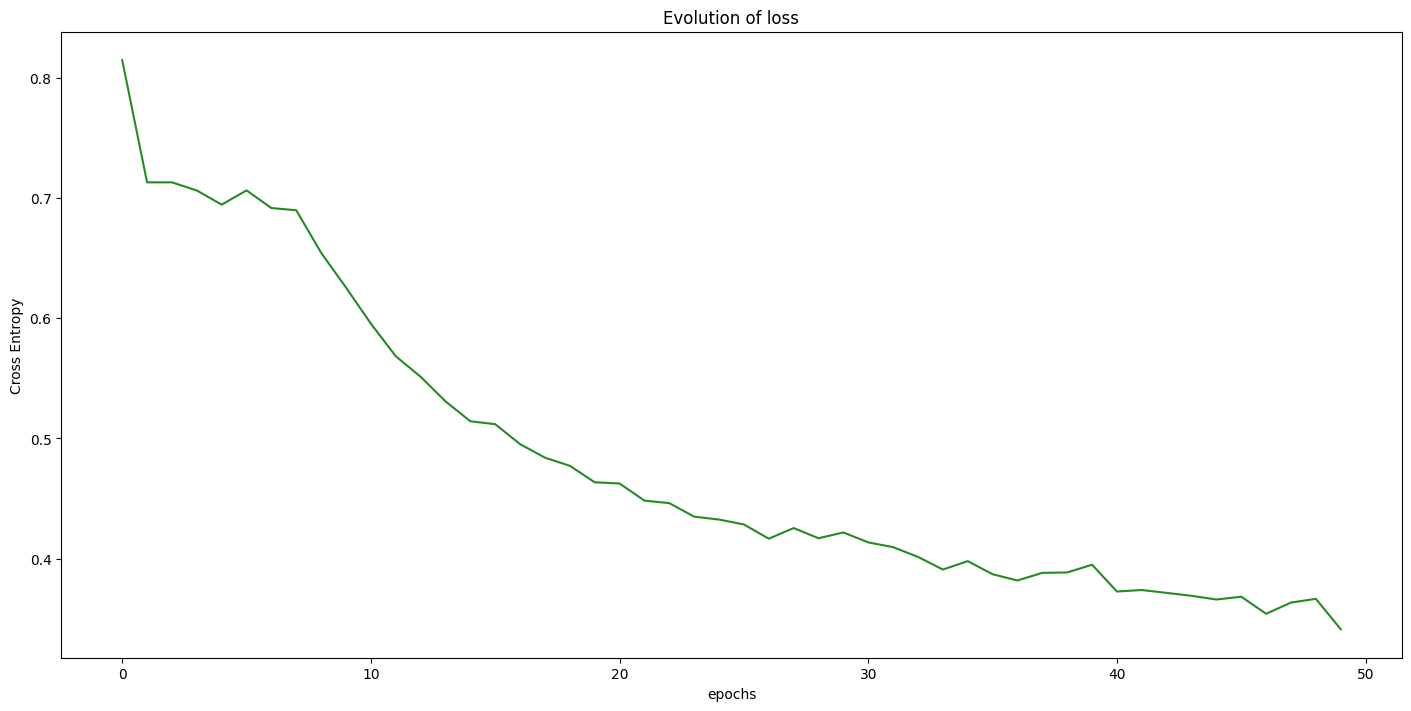

In [304]:
fig_nls, ax = plt.subplots(1, 1, figsize=(14, 7), constrained_layout=True)
ax.plot(all_loss_train_nls, 'forestgreen')

ax.set_title('Evolution of loss')
ax.set_xlabel('epochs')
ax.set_ylabel('Cross Entropy')

In [305]:
fig_nls.savefig(res_path+"/loss_evolution"+"/NLS-classifier_train_evolution.png", format="png", bbox_inches="tight")

torch.save(model_nls.state_dict(), res_path+"/models"+"/NLS-classifier_model.pth")

### Test

In [380]:
range_min, range_max = 0.05, 0.25
adv_min, adv_max = -3, 3

bounds = [(adv_min, adv_max), (range_min, range_max), (range_min, range_max)]

n_range = 8
n_adv = 8

range_vals = torch.linspace(range_min, range_max, n_range)
adv_vals = torch.linspace(adv_min, adv_max, n_adv)

R1, R2 = torch.meshgrid(range_vals, range_vals, indexing='ij')
R1, S = torch.meshgrid(R1.flatten(), adv_vals, indexing='ij')
R2, S = torch.meshgrid(R2.flatten(), adv_vals, indexing='ij')
theta_grid = torch.stack([S.flatten(), R1.flatten(), R2.flatten()], dim=1)

In [386]:
time_test_nls = time.time()

with torch.no_grad():
    for data_test, theta_test, _ in loader_grid_nls_test : 
        L_values = estimate_likelihood_surface(model_nls, data_test, theta_grid)
        output = theta_grid[torch.argmax(L_values,dim=0)]
        all_loss_test_nls = torch.abs(output - theta_test.squeeze(1)).detach().numpy()
        theta_final_nls = output.detach().numpy()
        
time_test_nls = time.time() - time_test_nls

print(f"\nTime to test : {time_test_nls:.2f}s")

print("Test loss :", np.mean(all_loss_test_nls,axis=0), "±", np.std(all_loss_test_nls,axis=0))

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 512/512 [00:09<00:00, 52.32it/s]

torch.Size([512, 60])
torch.Size([60])
torch.Size([60, 3])
torch.Size([60, 1, 3])

Time to test : 12.47s
(60, 3)
Test loss : [3.16666667 0.11084484 0.08942307] ± [2.20731108 0.06436333 0.05780276]


## Maximum likelihood

In [369]:
def matern_covariance_from_coords(coords, adv, range_time, range_space, std):

    t, s = coords

    s = s + t.copy() * adv

    sigma, nu = std, 1.

    d2 = ((t - t.T)**2 / range_time**2) + ((s - s.T)**2 / range_space**2)
    d = np.sqrt(d2 + 1e-12) 

    res = (sigma**2 * (2**(1-nu) / gamma(nu)) * (np.sqrt(2*nu) * d)**nu * kv(nu, np.sqrt(2*nu) * d))
    
    np.fill_diagonal(res, sigma**2)

    return res

In [370]:
def nll(theta, coords, values, eps=1e-6): 
    # https://soft.mines-paristech.fr/gstlearn/demos-latest/python/Tuto_LogLikelihood.html

    adv, range_time, range_space, std = theta
    cov = matern_covariance_from_coords(coords, adv, range_time, range_space, std)
    cov += eps * np.eye(cov.shape[0])

    L = linalg.cholesky(cov) 

    # solve Σ^{-1} @ values 
    alpha = linalg.cho_solve((L, False), values) 

    # Compute values.T @ Σ^{-1} @ values 
    quad = float(np.dot(values,alpha))

    # det term, https://math.stackexchange.com/questions/3158303/using-cholesky-decomposition-to-compute-covariance-matrix-determinant
    logdet = 2.0 * np.sum(np.log(np.diag(L)))

    return 0.5 * (logdet + quad + values.size * np.log(2.0 * np.pi))

In [371]:
range_min, range_max = 0.05, 0.5
adv_min, adv_max = -3, 3
std_min, std_max = .1, 1.

bounds = [(adv_min, adv_max), (range_min, range_max), (range_min, range_max), (std_min, std_max)]

In [372]:
def mle_matern(coords, values, theta0=(0,.2, .2, .5)):

    def obj(theta):
        return nll(theta, coords, values)

    res = minimize(obj, theta0, method="Nelder-Mead", bounds=bounds, options={"maxiter":2000})
    return res.x, res

In [374]:
all_loss_test_ML = np.zeros((len(dataset_grid_test),len(theta_names)))
theta_final_ML = np.zeros((len(dataset_grid_test),len(theta_names)))

dataset_mle = GridDataset(theta_size=test_size, time_size=time_size, space_size=space_size, deepset_size=1, missing_ratio=1/2)

grid = np.meshgrid(np.linspace(0,1,time_size), np.linspace(0,1,time_size), indexing='ij')
grid = ([grid[0].reshape(-1, 1), grid[1].reshape(-1, 1)])

time_test_ML = time.time()
time_simu_ML = 0
t_time_simu_ML = time.time()

for i, (data_test, theta_test, _) in enumerate(dataset_mle) : 

    time_simu_ML += time.time() - t_time_simu_ML

    mask = data_test[0,1].to(bool).flatten()

    grid_mask = (grid[0][mask], grid[1][mask])
    data = data_test[0,0].flatten()[mask]
    
    output, _ = mle_matern(grid, data_test[0,0].flatten().detach().numpy())

    all_loss_test_ML[i] = np.abs(output - theta_test.flatten().detach().numpy())
    theta_final_ML[i] = output

    t_time_simu_ML = time.time()
    print(i, end='|')
    print(output, theta_test.flatten().detach().numpy())
    

    # print(f"| RANGE {output[0]:.4f} - {theta_test[0]:.4f} = {abs(output[0]-theta_test[0]):.4f} | STD {output[1]:.4f} - {theta_test[1]:.4f} = {abs(output[1]-theta_test[1]):.4f} |")

time_test_ML = time.time() - time_test_ML - time_simu_ML

print(f"\n\nTime to test : {time_test_ML:.2f}s")

print("Test loss :", np.mean(all_loss_test_ML,axis=0), "±", np.std(all_loss_test_ML,axis=0))

0|[-2.47269433e-04  3.03765648e-01  5.00000000e-02  7.93744036e-01] [0.         0.20954012 0.18031953 0.88122459]
1|[0.02990794 0.09946028 0.05       0.79360793] [1.         0.07977951 0.19973274 0.96243274]
2|[-0.01316887  0.13793287  0.05        0.79973131] [-1.          0.07133396  0.16478789  0.70717151]


KeyboardInterrupt: 

## Conclusion

/tmp/ipykernel_703849/1227681480.py:14: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axs[i].boxplot(losses, labels=methods, patch_artist=True,
/tmp/ipykernel_703849/1227681480.py:14: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axs[i].boxplot(losses, labels=methods, patch_artist=True,
/tmp/ipykernel_703849/1227681480.py:14: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axs[i].boxplot(losses, labels=methods, patch_artist=True,
/tmp/ipykernel_703849/1227681480.py:14: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be d

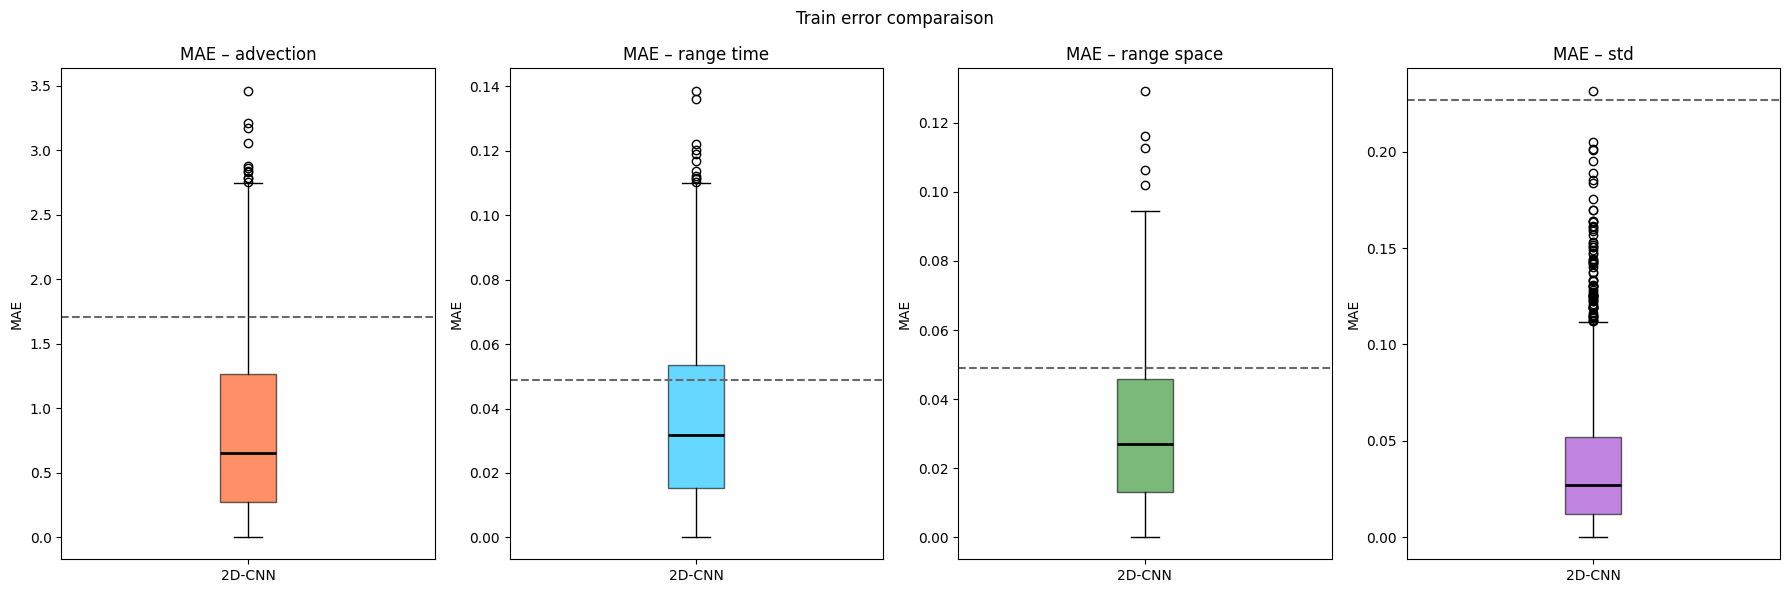

In [282]:
methods = ['2D-CNN']# , '1D1D-CNN','1DLSTM']

fig_box_train, axs = plt.subplots(1, len(theta_names), figsize=(18, 6))
based, _ = baseline_mae(dataset_grid)
    
for i, name in enumerate(theta_names):

    losses = [
        loss_final_train_2D[:, i],
        # loss_final_train_1D1D[:, i],
        # loss_final_train_1DLSTM[:, i],
    ]
    
    axs[i].boxplot(losses, tick_labels=methods, patch_artist=True,
                   boxprops=dict(facecolor=theta_colors[name]['train'], alpha=0.6), 
                   medianprops=dict(linestyle='-', linewidth=2, color='black'))
    axs[i].set_title("MAE – "+name)
    axs[i].set_ylabel("MAE")
    
    axs[i].axhline(based[i],color=theta_colors[name]['baseline'], ls='--', label='baseline '+name)
    # axs[i].legend()

plt.suptitle("Train error comparaison")
plt.tight_layout()
plt.show()

# fig_box_train.savefig(res_path+"/conclusion_graphs"+"/score_train.pdf", format="pdf", bbox_inches="tight")
fig_box_train.savefig(res_path+"/conclusion_graphs"+"/score_train.png", format="png", bbox_inches="tight")

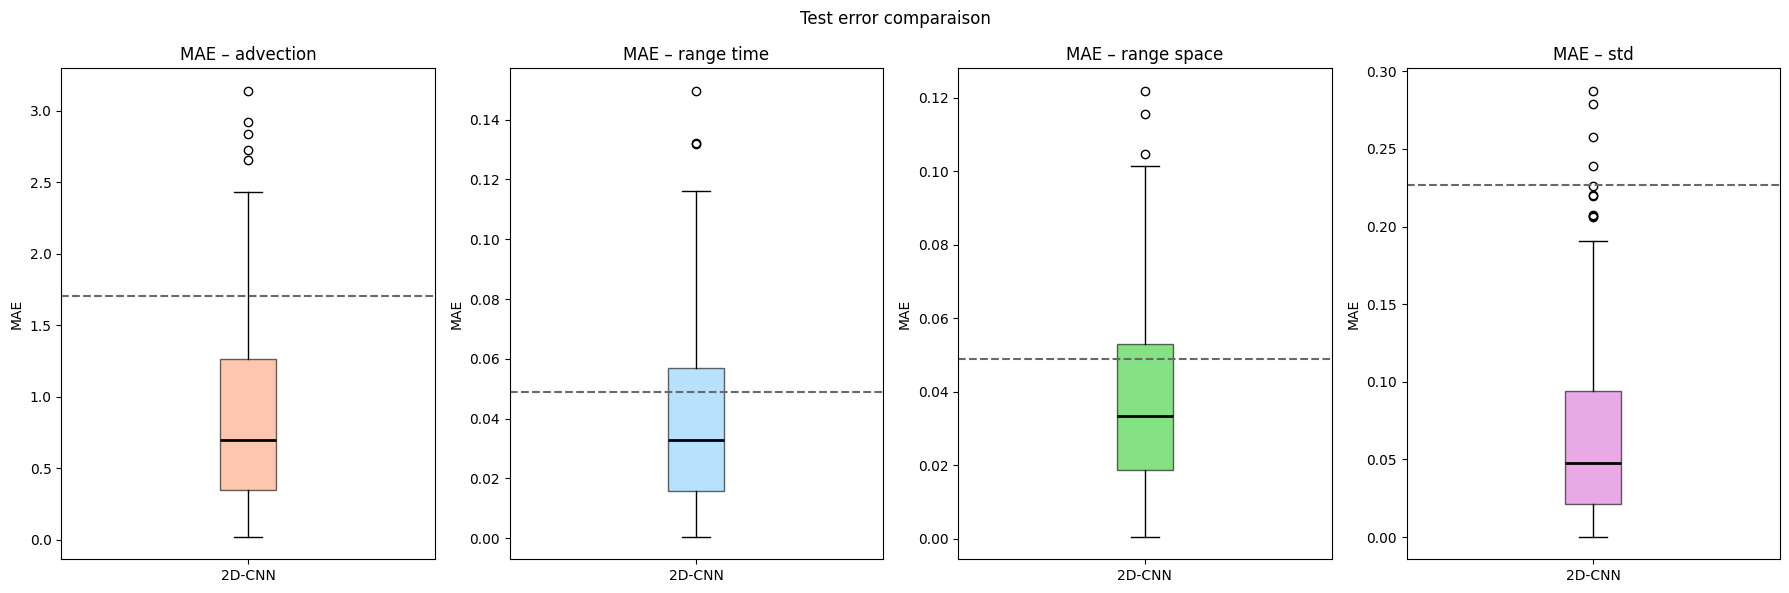

FileNotFoundError: [Errno 2] No such file or directory: 'results/test_spationtemporal_2D/conclusion_graphs/score_test.png'

In [375]:
methods = ['2D-CNN']# , '1D1D-CNN','1DLSTM']

fig_box_test, axs = plt.subplots(1, len(theta_names), figsize=(18, 6))
based, _ = baseline_mae(dataset_grid)
    
for i, name in enumerate(theta_names):

    losses = [
        abs(theta_final_test_2D[:, i] - dataset_grid_test.get_theta()[:, i]),
        # abs(theta_final_test_1D1D[:, 0] - dataset_grid_test.get_theta()[:, 0]),
        # abs(theta_final_test_1DLSTM[:, 0] - dataset_grid_test.get_theta()[:, 0]),
        # all_loss_test_nls[:,0]
    ]
    
    axs[i].boxplot(losses, tick_labels=methods, patch_artist=True,
                   boxprops=dict(facecolor=theta_colors[name]['test'], alpha=0.6), 
                   medianprops=dict(linestyle='-', linewidth=2, color='black'))
    axs[i].set_title("MAE – "+name)
    axs[i].set_ylabel("MAE")
    
    axs[i].axhline(based[i],color=theta_colors[name]['baseline'], ls='--', label='baseline '+name)
    # axs[i].legend()

plt.suptitle("Test error comparaison")
plt.tight_layout()
plt.show()

# fig_box_test.savefig(res_path+"/conclusion_graphs"+"/score_test.pdf", format="pdf", bbox_inches="tight")
fig_box_test.savefig(res_path+"/conclusion_graphs"+"/score_test.png", format="png", bbox_inches="tight")

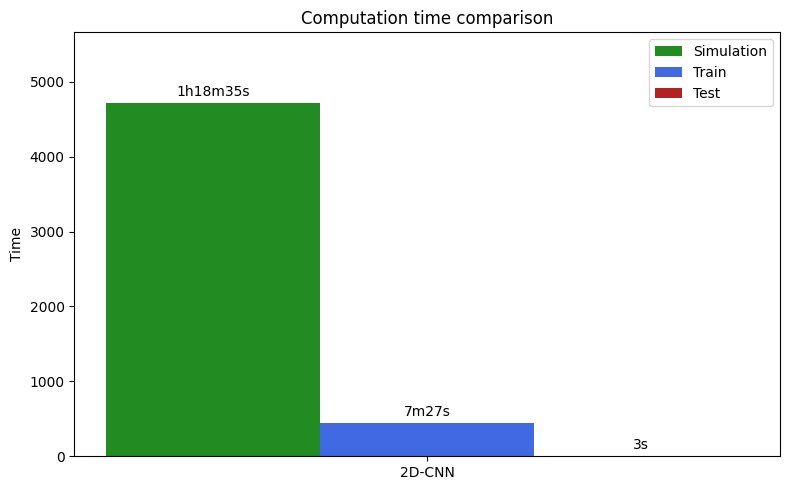

In [284]:
### Time



def format_seconds(s):
    h, m, s = int(s//3600), int((s%3600)//60), int(s%60)
    return f"{h}h{m}m{s}s" if h > 0 else (f"{m}m{s}s" if m > 0 else f"{s}s")

methods = ['2D-CNN']
simu_times = [time_simu_2D]
train_times = [time_train_2D] #, time_train_1D1D, time_train_1DLSTM]  
test_times = [time_test_2D] #, time_test_1D1D, time_test_1DLSTM]

x = np.arange(len(methods))
width = 0.2

fig_time, ax = plt.subplots(figsize=(8, 5))

bar0 = ax.bar(x - width, simu_times, width, label='Simulation', color='forestgreen')
bar1 = ax.bar(x, train_times, width, label='Train', color='royalblue')
bar2 = ax.bar(x + width, test_times, width, label='Test', color='firebrick')

for b, t in zip([bar0, bar1, bar2], [simu_times, train_times, test_times]):
    labels = [format_seconds(val) for val in t]
    ax.bar_label(b, labels=labels, padding=3)

ax.set_xticks(x)
ax.set_xticklabels(methods)
ax.set_ylabel("Time")
ax.set_title("Computation time comparison")
ax.legend()

ax.margins(y=0.2) 

plt.tight_layout()
plt.show()

# fig_time.savefig(res_path+"/conclusion_graphs"+"/time.pdf", format="pdf", bbox_inches="tight")
fig_time.savefig(res_path+"/conclusion_graphs"+"/time.png", format="png", bbox_inches="tight")

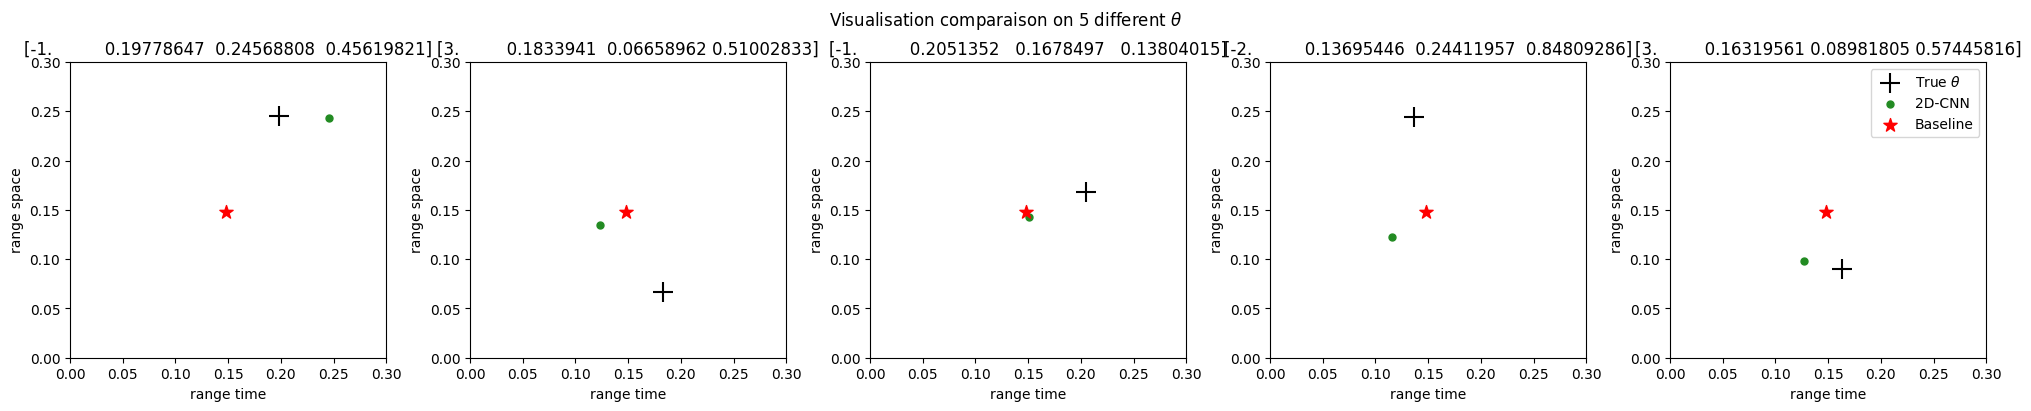

In [285]:
range_min, range_max = 0.05, 0.25
adv_min, adv_max = -3, 3

methods = ['2D-CNN']#, '1D1D','1DLSTM'] #,'CNN-NLS']
colors = ["forestgreen"]#, "firebrick", "royalblue"] #, "orchid"]
thetas_final = [theta_final_test_2D]#, theta_final_test_1D1D, theta_final_test_1DLSTM]

fig_target, axs = plt.subplots(1, 5, figsize=(20,4), constrained_layout=True)

_, based_theta = baseline_mae(dataset_grid)

for j in range(min(deepset_size,5)):
    
    true_theta = dataset_grid_test.get_theta()[j].detach().numpy()

    axs[j].scatter(true_theta[1], true_theta[2], s=200, color='black', marker="+", label=r"True $\theta$") 
        
    axs[j].set_xlabel('range time')
    axs[j].set_ylabel('range space')
    axs[j].set_title(str(true_theta))

    axs[j].set_xlim([range_min-.05, range_max+.05])
    axs[j].set_ylim([range_min-.05, range_max+.05])

    for method, color, thetas in zip(methods, colors, thetas_final) :

        axs[j].scatter(thetas[np.arange(1)+j,1],
                       thetas[np.arange(1)+j,2],
                       s=100, color=color, marker=".", label=method) 

    axs[j].scatter(based_theta[1],based_theta[2], s=100, color='red', marker="*",label='Baseline')

plt.suptitle(r"Visualisation comparaison on 5 different $\theta$")
plt.legend()

# fig_target.savefig(res_path+"/conclusion_graphs"+"/target.pdf", format="pdf", bbox_inches="tight")
fig_target.savefig(res_path+"/conclusion_graphs"+"/target.png", format="png", bbox_inches="tight")

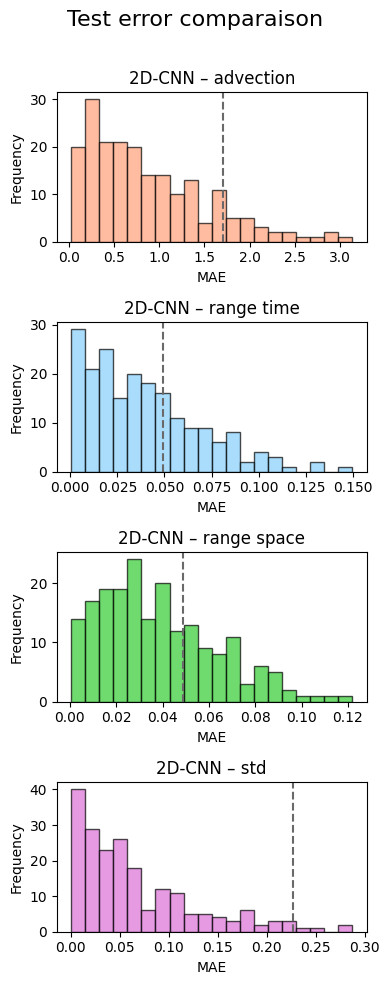

In [286]:
methods = ['2D-CNN']#, '1D1D','1DLSTM']

fig_hist, axs = plt.subplots(len(theta_names), len(methods), figsize=(len(theta_names), 10*len(methods)),squeeze=False)
fig_hist.suptitle("Test error comparaison", fontsize=16)

for i, name in enumerate(theta_names):
    for j, method in enumerate(methods):

        losses = [
            abs(theta_final_test_2D[:, i] - dataset_grid_test.get_theta()[:, i]),
            # abs(theta_final_test_1D1D[:, i] - dataset_grid_test.get_theta()[:, i]),
            # abs(theta_final_test_1DLSTM[:, i] - dataset_grid_test.get_theta()[:, i]),
            # all_loss_test_nls[:,0]
        ]

        axs[i, j].hist(losses[j], bins=20, color=theta_colors[name]['test'], alpha=0.7, edgecolor='black')
        axs[i, j].axvline(based[i], color=theta_colors[name]['baseline'], linestyle='--', label='Baseline range')
        axs[i, j].set_title(f"{method} – {name}")
        axs[i, j].set_xlabel("MAE")
        axs[i, j].set_ylabel("Frequency")
        # axs[i, j].legend()

plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

fig_hist.savefig(res_path+"/conclusion_graphs"+"/score_test_hist.png", format="png", bbox_inches="tight")

FileNotFoundError: [Errno 2] No such file or directory: 'results/test_spationtemporal_2D/conclusion_graphs/visualisation.png'

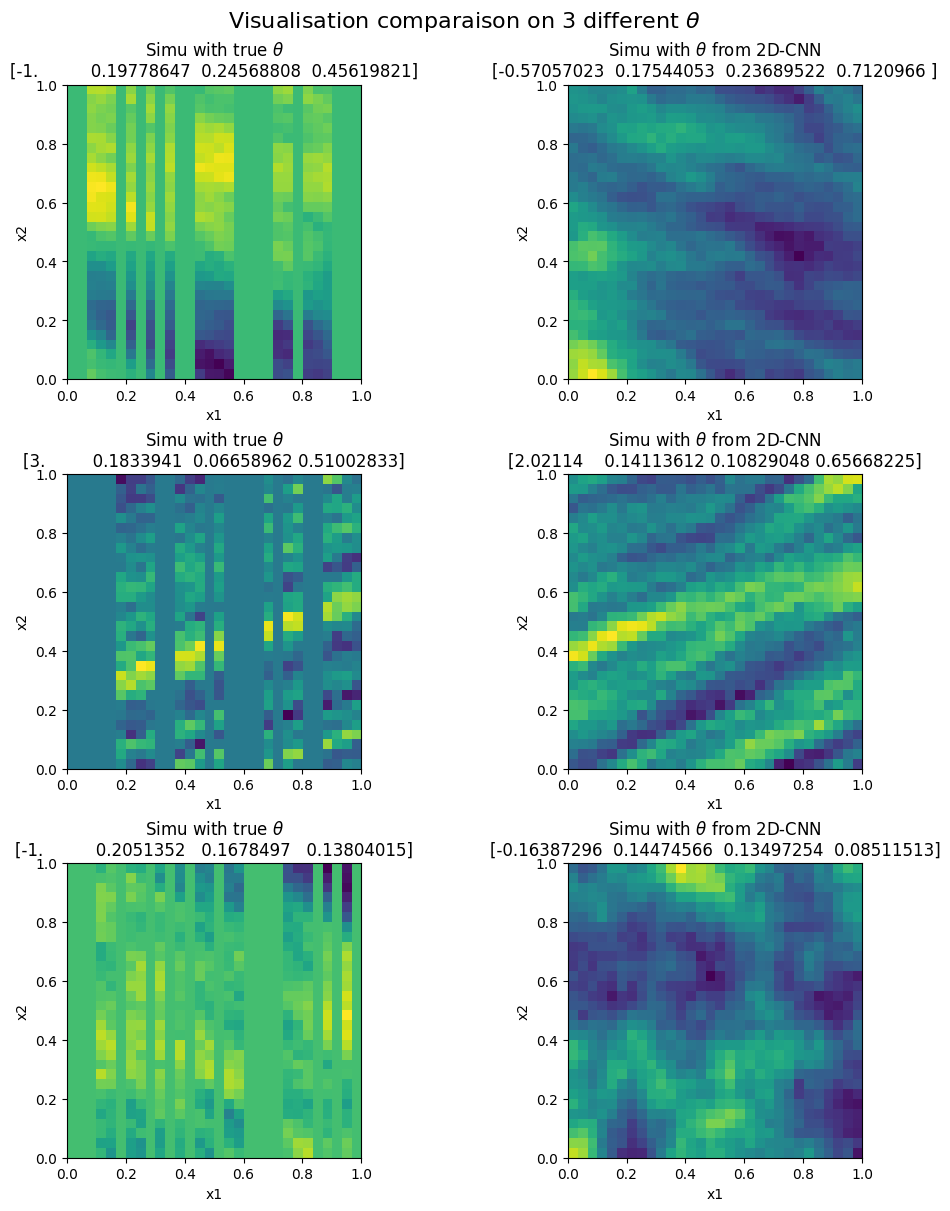

In [290]:
methods = ['2D-CNN']#, '1D1D','1DLSTM']
models = [model_2D]#, model_1D1D, model_1DLSTM]
# thetas_final = [theta_final_test_2D, theta_final_test_1D1D, theta_final_test_1DLSTM]
# losses = [all_loss_test_2D[-1], all_loss_test_1D1D[-1], all_loss_test_1DLSTM[-1]]

n = 3
p = len(methods)+1
fig_map, axs = plt.subplots(n, p, figsize=(5*p,n*4), constrained_layout=True)

for i in range(n):
    sample, true_theta, _ = dataset_grid_test[i]
    true_theta = true_theta[0].detach().numpy()
    
    axs[i,0].imshow(sample[0][0], cmap='viridis', extent=[0,1,0,1])
        
    axs[i,0].set_xlabel('x1')
    axs[i,0].set_ylabel('x2')
    axs[i,0].set_title(r'Simu with true $\theta$'+'\n'+str(true_theta))
    
    for j, (method, model) in enumerate(zip(methods, models)) :

        theta_pred = model(sample.float(), deepset=torch.tensor([0]))[0]
        sample_pred = simulate_matern_grid(time_size, space_size, torch.round(theta_pred[0]).to(int).detach().numpy(), torch.max(theta_pred[1],torch.tensor(0.05)), torch.max(theta_pred[2],torch.tensor(0.05)), torch.max(theta_pred[3],torch.tensor(0.1)), deepset_size=1)[0]
            
        # sample = sample['Simu'].reshape(100, 100)
        axs[i,j+1].imshow(sample_pred[0], cmap='viridis', extent=[0,1,0,1]) #, origin='lower', extent=[0,1,0,1], cmap='viridis')
            
        axs[i,j+1].set_xlabel('x1')
        axs[i,j+1].set_ylabel('x2')
        axs[i,j+1].set_title(r'Simu with $\theta$ from '+method+'\n'+str(theta_pred.detach().numpy()))
        

fig_map.suptitle(r"Visualisation comparaison on "+str(n)+r" different $\theta$", fontsize=16)

# fig_map.savefig(res_path+"/conclusion_graphs"+"/visualisation.pdf", format="pdf", bbox_inches="tight")
fig_map.savefig(res_path+"/conclusion_graphs"+"/visualisation.png", format="png", bbox_inches="tight")

plt.show()

In [69]:
results = {
    "all_loss_train": {
        "2D": all_loss_train_2D,
        "1D1D": all_loss_train_1D1D,
        "1DLSTM": all_loss_train_1DLSTM,
    },
    "all_loss_test": {
        "2D": all_loss_test_2D,
        "1D1D": all_loss_test_1D1D,
        "1DLSTM": all_loss_test_1DLSTM,
        # "NLS": all_loss_test_nls,
    },
    "loss_final": {
        "2D": loss_final_train_2D,
        "1D1D": loss_final_train_1D1D,
        "1DLSTM": loss_final_train_1DLSTM,
    },
    "theta_final": {
        "2D": theta_final_test_2D,
        "1D1D": theta_final_test_1D1D,
        "1DLSTM": theta_final_test_1DLSTM,
        # "NLS": theta_final_nls,
    },
    "times": {
        "time_train_2D": time_train_2D,
        "time_test_2D": time_test_2D,
        "time_train_1D1D": time_train_1D1D,
        "time_test_1D1D": time_test_1D1D,
        "time_train_1DLSTM": time_train_1DLSTM,
        "time_test_1DLSTM": time_test_1DLSTM,
        # "time_train_nls": time_train_nls,
        # "time_test_nls": time_test_nls,
    },
}

torch.save(results, res_path + "/results.pt")

NameError: name 'all_loss_train_2D' is not defined